# Task 5 — Engineered-feature EDA

Read raw data independently, mask invalid login coordinates, add row-wise behavior summaries, inspect them, and save a test-only dataset. No labels or offline F₃ are available.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "src" / "pipeline" / "save_data.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
SRC = ROOT / "src"
RAW = SRC / "task5" / "data" / "raw"
from src.pipeline.random_seed import set_seed
SEED = set_seed()
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ID = "player_id"
TARGET = "is_anomaly"

## Verify raw data and leakage

In [2]:
test_raw = pd.read_csv(RAW / "test-outdate-12-11-2026.csv")
assert test_raw.shape[1] == 123
assert ID in test_raw and TARGET not in test_raw
assert test_raw[ID].notna().all() and test_raw[ID].is_unique
feature_cols = test_raw.columns.drop(ID).tolist()
assert len(feature_cols) == 122
assert all(pd.api.types.is_numeric_dtype(test_raw[c]) for c in feature_cols)
assert np.isfinite(test_raw[feature_cols].to_numpy(dtype=float)[~test_raw[feature_cols].isna().to_numpy()]).all()
print(f"{len(test_raw):,} rows, {len(feature_cols)} numeric features, no labels")
display(test_raw.head(3))

25,889 rows, 122 numeric features, no labels


,player_id,login_count_1,login_count_2,login_count_3,login_count_4,login_lat_1,login_lon_1,login_lat_2,login_lon_2,login_lat_3,...,guild_changes_1,guild_changes_2,guild_changes_3,guild_changes_4,account_age_days,behavior_stability,password_changed,vpn_usage,suspicious_login_time,mass_item_sale
0,P005807,90.311349,90.547639,85.696177,85.467099,NaN,-73.275855,39.258196,-73.608702,38.097200,...,2.0,2.0,2.0,2.0,363.872386,0.726597,0.0,0.0,0.0,0.0
1,P009995,92.522163,67.906460,113.678435,98.321423,-40.247854,-126.380420,NaN,-126.226320,-39.987100,...,0.0,0.0,0.0,1.0,1218.236865,0.774107,0.0,0.0,1.0,0.0
2,P021209,26.208497,24.837245,28.142424,31.534804,9.023819,-137.129311,8.837883,-138.033738,9.539285,...,0.0,-1.0,-1.0,1.0,502.036836,0.851379,0.0,0.0,0.0,0.0


In [3]:
quality = pd.DataFrame({"dtype": test_raw.dtypes.astype(str),
                        "missing": test_raw.isna().sum(),
                        "missing_pct": test_raw.isna().mean().mul(100).round(2),
                        "unique": test_raw.nunique(dropna=True)})
display(quality.sort_values("missing", ascending=False).head(20))
print("Duplicate player IDs:", test_raw[ID].duplicated().sum())
print("Entirely missing feature rows:", test_raw[feature_cols].isna().all(axis=1).sum())
print("Constant/empty feature columns:", quality.loc[feature_cols].query("unique <= 1").index.tolist())

,dtype,missing,missing_pct,unique
ip_hash_entropy_4,float64,1328,5.13,24561
session_duration_std_4,float64,1324,5.11,24565
friend_adds_1,float64,1319,5.09,23376
kda_mean_4,float64,1316,5.08,24573
login_count_4,float64,1314,5.08,24575
activity_level_4,float64,1314,5.08,24575
friend_adds_3,float64,1313,5.07,23375
location_changes_2,float64,1305,5.04,24584
accuracy_std_3,float64,1305,5.04,24584
kda_std_3,float64,1302,5.03,24587


Duplicate player IDs: 0
Entirely missing feature rows: 0
Constant/empty feature columns: []


## Raw-data context before extraction

The same quality and four-period checks are repeated here because this notebook stands alone; it does not use variables from the original EDA notebook.

,missing_pct,median
ip_hash_entropy_4,5.13,0.55
session_duration_std_4,5.11,24.67
friend_adds_1,5.09,8.73
kda_mean_4,5.08,2.16
login_count_4,5.08,58.58
activity_level_4,5.08,0.99
friend_adds_3,5.07,9.36
accuracy_std_3,5.04,6.43
location_changes_2,5.04,1.42
kda_std_3,5.03,0.49


,positive_pct_of_observed,missing_pct
password_changed,6.27,4.99
vpn_usage,15.70,5.00
suspicious_login_time,4.93,4.72
mass_item_sale,2.73,4.94


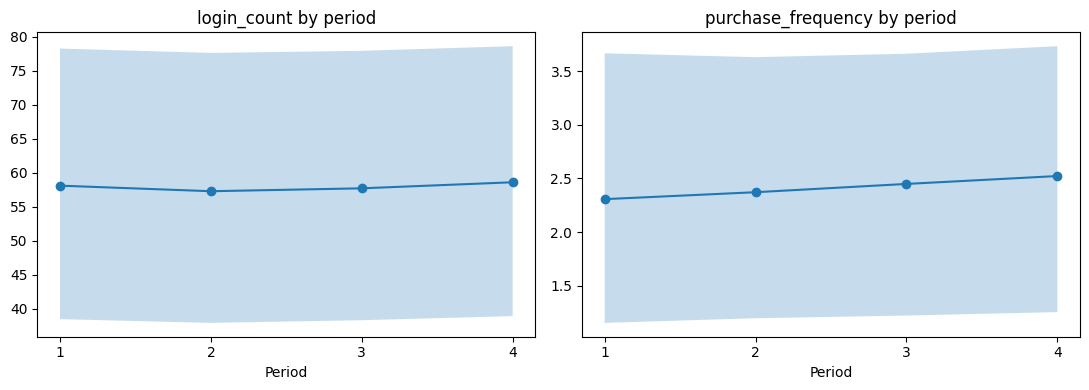

In [4]:
display(pd.DataFrame({"missing_pct": test_raw[feature_cols].isna().mean().mul(100),
                      "median": test_raw[feature_cols].median()}).sort_values("missing_pct", ascending=False).head(15).round(2))
flag_cols = ["password_changed", "vpn_usage", "suspicious_login_time", "mass_item_sale"]
display(pd.DataFrame({"positive_pct_of_observed": 100*test_raw[flag_cols].gt(0).sum()/test_raw[flag_cols].notna().sum(),
                      "missing_pct": 100*test_raw[flag_cols].isna().mean()}).round(2))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for family, ax in zip(["login_count", "purchase_frequency"], axes):
    cols = [f"{family}_{i}" for i in range(1,5)]
    median = test_raw[cols].median().to_numpy()
    p25 = test_raw[cols].quantile(.25).to_numpy()
    p75 = test_raw[cols].quantile(.75).to_numpy()
    ax.plot(range(1,5), median, marker="o")
    ax.fill_between(range(1,5), p25, p75, alpha=.25)
    ax.set_xticks([1,2,3,4])
    ax.set_title(family + " by period")
    ax.set_xlabel("Period")
fig.tight_layout()
plt.show()

## Feature extraction

Four-period mean, spread, range, first-to-last change, recent shift, and largest step capture level and behavior changes. These are common short-series summaries documented by [tsfresh](https://tsfresh.readthedocs.io/en/v0.20.3/text/list_of_features.html). Login location displacement follows the account-risk idea of unusual travel in [Microsoft Entra](https://learn.microsoft.com/en-us/entra/id-protection/concept-identity-protection-risks), but **without timestamps it is distance only, never an “impossible travel” flag**. Missing values remain missing for model-stage imputation.

In [5]:
# Retain all IDs and periods; mask invalid coordinate pairs before feature extraction.
test_base = test_raw.copy()
for period in range(1, 5):
    lat_col, lon_col = f"login_lat_{period}", f"login_lon_{period}"
    invalid_pair = (test_base[lat_col].notna() & ~test_base[lat_col].between(-90, 90)) | (test_base[lon_col].notna() & ~test_base[lon_col].between(-180, 180))
    test_base.loc[invalid_pair, [lat_col, lon_col]] = np.nan
    assert test_base[lat_col].dropna().between(-90, 90).all()
    assert test_base[lon_col].dropna().between(-180, 180).all()
print("Players with invalid coordinate pairs masked:", int(((test_raw.filter(regex=r'^login_(lat|lon)_[1-4]$') != test_base.filter(regex=r'^login_(lat|lon)_[1-4]$')) & test_raw.filter(regex=r'^login_(lat|lon)_[1-4]$').notna()).any(axis=1).sum()))

# All calculations are within one player row; no statistics are fitted across players.
# Four observations support simple summaries and changes, not complex spectral estimates.
FAMILIES = [
    "login_count", "location_changes", "device_count", "ip_hash_entropy",
    "login_time_variance", "session_duration_mean", "play_pattern_consistency",
    "activity_level", "skill_rating", "reaction_time_mean", "purchase_frequency",
    "purchase_amount_mean", "currency_transfers", "communication_frequency",
]

def haversine_km(lat1, lon1, lat2, lon2):
    a1, b1, a2, b2 = [np.radians(x.astype(float)) for x in (lat1, lon1, lat2, lon2)]
    delta = np.sin((a2-a1)/2)**2 + np.cos(a1)*np.cos(a2)*np.sin((b2-b1)/2)**2
    return 6371.0 * 2 * np.arcsin(np.sqrt(np.clip(delta, 0, 1)))

def add_task5_features(frame):
    out = frame.copy()
    out["missing_feature_count"] = out[feature_cols].isna().sum(axis=1)
    for family in FAMILIES:
        cols = [f"{family}_{i}" for i in range(1, 5)]
        assert all(c in out for c in cols), family
        window = out[cols]
        out[f"{family}_mean4"] = window.mean(axis=1)
        out[f"{family}_std4"] = window.std(axis=1)
        out[f"{family}_range4"] = window.max(axis=1) - window.min(axis=1)
        out[f"{family}_delta41"] = out[cols[3]] - out[cols[0]]
        out[f"{family}_recent_shift"] = out[cols[3]] - out[cols[:3]].mean(axis=1)
        diffs = pd.concat([(out[cols[i+1]] - out[cols[i]]).abs() for i in range(3)], axis=1)
        out[f"{family}_max_step"] = diffs.max(axis=1)
    for i in range(1, 4):
        out[f"login_move_km_{i}{i+1}"] = haversine_km(
            out[f"login_lat_{i}"], out[f"login_lon_{i}"],
            out[f"login_lat_{i+1}"], out[f"login_lon_{i+1}"],
        )
    move_cols = [f"login_move_km_{i}{i+1}" for i in range(1, 4)]
    out["login_move_max_km"] = out[move_cols].max(axis=1)
    out["login_move_total_km"] = out[move_cols].sum(axis=1, min_count=1)
    out["security_flag_count"] = out[["password_changed", "vpn_usage", "suspicious_login_time", "mass_item_sale"]].sum(axis=1, min_count=1)
    return out

test_featured = add_task5_features(test_base)
new_features = test_featured.columns.difference(test_raw.columns).tolist()
assert test_featured[test_base.columns].equals(test_base)
assert test_featured[ID].equals(test_raw[ID])
assert TARGET not in test_featured
print("New row-wise features:", len(new_features), "total model features:", len(test_featured.columns)-1)

Players with invalid coordinate pairs masked: 207


New row-wise features: 91 total model features: 213


## Check engineered columns

In [6]:
display(pd.DataFrame({"missing_pct": test_featured[new_features].isna().mean().mul(100).round(2),
                      "median": test_featured[new_features].median(),
                      "p99": test_featured[new_features].quantile(.99)}).head(30))
assert np.isfinite(test_featured.drop(columns=ID).to_numpy(dtype=float)[~test_featured.drop(columns=ID).isna().to_numpy()]).all()

,missing_pct,median,p99
activity_level_delta41,9.68,-0.000783,0.471389
activity_level_max_step,0.69,0.212441,0.614771
activity_level_mean4,0.00,0.989712,1.590535
activity_level_range4,0.00,0.251715,0.630227
activity_level_recent_shift,5.09,-0.000832,0.313747
activity_level_std4,0.05,0.116466,0.287584
communication_frequency_delta41,9.42,0.000883,0.279203
communication_frequency_max_step,0.71,0.164752,0.486400
communication_frequency_mean4,0.00,0.742332,1.267210
communication_frequency_range4,0.00,0.184615,0.488570


## What the engineered dataset adds

Compare feature counts, missingness, and representative distributions. The geographic features are displacement in kilometres; no timestamps exist to call a move “impossible travel.” Extreme values are clipped only for the displayed histograms, never in the saved dataset.

,dataset,features,missing_cells,missing_pct,constant_features
0,raw,122,153872,4.87,0
1,engineered,213,224984,4.08,0


,min,p01,p25,median,p75,p99,max,missing_pct
missing_feature_count,0.00,1.00,4.00,6.00,7.00,12.00,21.00,0.00
login_count_recent_shift,-33.86,-20.03,-4.59,0.00,4.50,20.16,34.67,5.09
device_count_max_step,0.00,0.00,1.00,1.00,2.00,2.00,3.00,0.68
purchase_frequency_recent_shift,-2.86,-1.45,-0.24,0.00,0.26,1.92,24.06,4.87
currency_transfers_max_step,0.00,0.02,0.56,1.25,2.22,17.70,49.51,0.63
login_move_max_km,1.38,24.42,85.21,116.32,151.75,4685.16,12332.06,2.53
security_flag_count,0.00,0.00,0.00,0.00,1.00,2.00,4.00,0.00


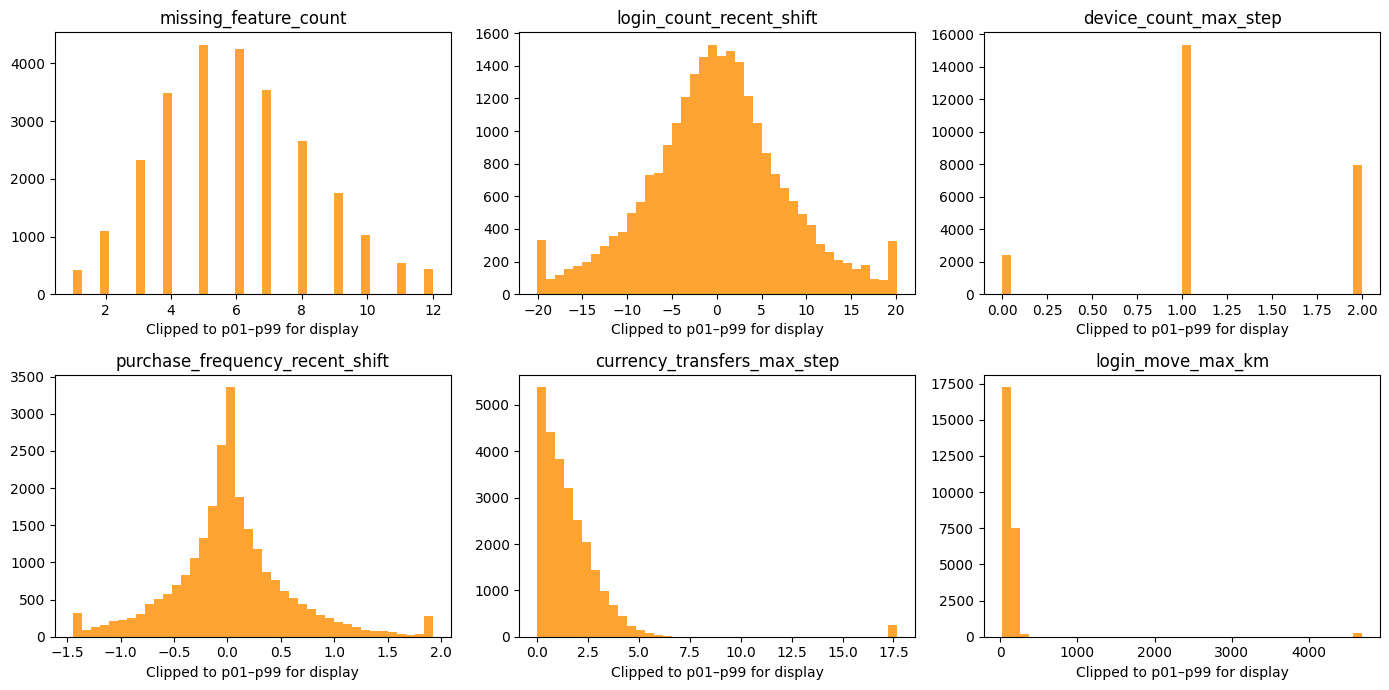

,players
security_flag_count,
0.0,19378
1.0,5784
2.0,675
3.0,51
4.0,1


In [7]:
summary = pd.DataFrame([
    {"dataset":"raw", "features":len(feature_cols), "missing_cells":int(test_raw[feature_cols].isna().sum().sum()),
     "missing_pct":100*test_raw[feature_cols].isna().to_numpy().mean(), "constant_features":int((test_raw[feature_cols].nunique(dropna=True)<=1).sum())},
    {"dataset":"engineered", "features":len(test_featured.columns)-1, "missing_cells":int(test_featured.drop(columns=ID).isna().sum().sum()),
     "missing_pct":100*test_featured.drop(columns=ID).isna().to_numpy().mean(), "constant_features":int((test_featured.drop(columns=ID).nunique(dropna=True)<=1).sum())},
])
display(summary.round(2))
review = ["missing_feature_count", "login_count_recent_shift", "device_count_max_step",
          "purchase_frequency_recent_shift", "currency_transfers_max_step", "login_move_max_km", "security_flag_count"]
feature_quantiles = test_featured[review].quantile([0, .01, .25, .5, .75, .99, 1]).T
feature_quantiles.columns = ["min", "p01", "p25", "median", "p75", "p99", "max"]
feature_quantiles["missing_pct"] = test_featured[review].isna().mean().mul(100)
display(feature_quantiles.round(2))
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for col, ax in zip(review[:6], axes.flat):
    lo, hi = test_featured[col].quantile([.01, .99])
    ax.hist(test_featured[col].clip(lo, hi).dropna(), bins=40, color="darkorange", alpha=.8)
    ax.set_title(col)
    ax.set_xlabel("Clipped to p01–p99 for display")
fig.tight_layout()
plt.show()
display(test_featured["security_flag_count"].value_counts(dropna=False).sort_index().rename("players").to_frame())

### Coordinate check

Invalid coordinate pairs are masked before distance calculation. Long distances from valid coordinates remain descriptive signals, not confirmed anomalies.

In [8]:
invalid_geo = pd.Series(False, index=test_raw.index)
geo_quality = []
for period in range(1, 5):
    lat = test_raw[f"login_lat_{period}"]
    lon = test_raw[f"login_lon_{period}"]
    invalid_lat = lat.notna() & ~lat.between(-90, 90)
    invalid_lon = lon.notna() & ~lon.between(-180, 180)
    invalid_geo |= invalid_lat | invalid_lon
    geo_quality.append({"period":period, "invalid_lat":int(invalid_lat.sum()),
                        "invalid_lon":int(invalid_lon.sum())})
display(pd.DataFrame(geo_quality))
print("Affected players:", int(invalid_geo.sum()),
      "Extreme derived max distance (>2000 km):", int(test_featured["login_move_max_km"].gt(2000).sum()))
print("Median max distance, valid-coordinate rows:",
      round(float(test_featured.loc[~invalid_geo, "login_move_max_km"].median()), 2))

,period,invalid_lat,invalid_lon
0,1,0,31
1,2,0,27
2,3,4,46
3,4,56,102


Affected players: 207 Extreme derived max distance (>2000 km): 329
Median max distance, valid-coordinate rows: 116.47


## Inspect engineered relationships and leakage

Look for redundant formulas and confirm the ID and unavailable label are not model features. Correlation here is descriptive only, since all rows are unlabeled Test data.

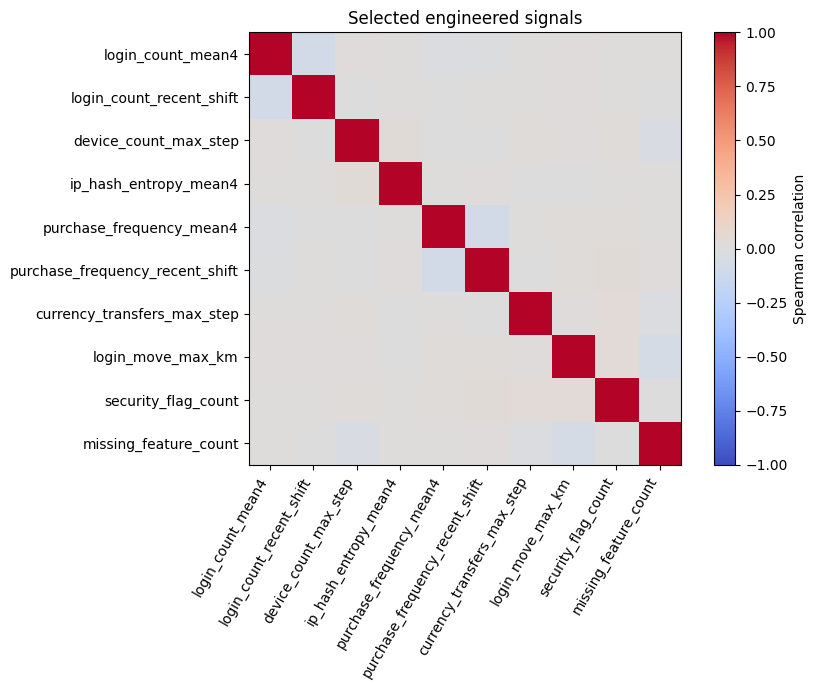

No label, ID-derived, or cross-row fitted features were added.


In [9]:
relationship_cols = ["login_count_mean4", "login_count_recent_shift", "device_count_max_step",
                     "ip_hash_entropy_mean4", "purchase_frequency_mean4", "purchase_frequency_recent_shift",
                     "currency_transfers_max_step", "login_move_max_km", "security_flag_count", "missing_feature_count"]
corr = test_featured[relationship_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=60, ha="right")
ax.set_yticks(range(len(corr)), corr.index)
fig.colorbar(im, ax=ax, label="Spearman correlation")
ax.set_title("Selected engineered signals")
fig.tight_layout()
plt.show()
assert ID not in new_features and TARGET not in test_featured
assert test_featured[test_base.columns].equals(test_base)
print("No label, ID-derived, or cross-row fitted features were added.")

## Save engineered test-only artifact

In [10]:
from src.pipeline.save_data import save_data
feature_info = save_data(
    task=5, name="eda_1_v1", test=test_featured,
    card={"source": "task5/data/raw/test-outdate-12-11-2026.csv", "features": "four-period summaries, recent changes, login displacement, missing/flag counts", "scope": "test-only; instructor-approved unsupervised fitting", "coordinate_cleaning": "invalid latitude/longitude pairs masked before distance calculation"},
)
print(feature_info["splits"]["test"]["path"])

task5/data/eda/eda_1_v1-test.parquet
